# Analyse exploratoire des données — BRFSS 2014

L’objectif est de comprendre la structure du jeu de données, de repérer les
valeurs manquantes et d’explorer les variables utiles au projet de prédiction
du diabète.

1-Importation et aperçu des données

In [7]:
from pathlib import Path
import pandas as pd

fichier = Path(
    r"D:\EMSI\ML\Projet\ML_Diabetes_Prediction\BRFSS_2014\2014.csv"
)

df = pd.read_csv(fichier, low_memory=False)

lignes, colonnes = df.shape
print(f"Nombre de lignes : {lignes}")
print(f"Nombre de colonnes : {colonnes}")

display(df.head())

Nombre de lignes : 464664
Nombre de colonnes : 279


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,...,_FOBTFS,_CRCREC,_AIDTST3,_IMPEDUC,_IMPMRTL,_IMPHOME,RCSBRAC1,RCSRACE1,RCHISLA1,RCSBIRTH
0,1.0,1.0,b'01172014',b'01',b'17',b'2014',1100.0,2.014000e+09,2.014000e+09,1.0,...,2.0,1.0,2.0,5.0,1.0,1.0,NaN,b'',b'',b''
1,1.0,1.0,b'01072014',b'01',b'07',b'2014',1100.0,2.014000e+09,2.014000e+09,1.0,...,2.0,2.0,2.0,4.0,1.0,1.0,NaN,b'',b'',b''
2,1.0,1.0,b'01092014',b'01',b'09',b'2014',1100.0,2.014000e+09,2.014000e+09,1.0,...,2.0,2.0,2.0,6.0,1.0,1.0,NaN,b'',b'',b''
3,1.0,1.0,b'01072014',b'01',b'07',b'2014',1100.0,2.014000e+09,2.014000e+09,1.0,...,2.0,1.0,2.0,6.0,3.0,1.0,NaN,b'',b'',b''
4,1.0,1.0,b'01162014',b'01',b'16',b'2014',1100.0,2.014000e+09,2.014000e+09,1.0,...,2.0,1.0,2.0,5.0,1.0,1.0,NaN,b'',b'',b''


2-Diagnostic des valeurs manquantes

In [8]:
print("Nombre de colonnes par type :")
display(df.dtypes.value_counts())

taux_manquants = df.isna().mean().mul(100)

print("Les 10 colonnes les plus vides (%) :")
display(taux_manquants.nlargest(10).round(2))

Nombre de colonnes par type :


float64    271
str          8
Name: count, dtype: int64

Les 10 colonnes les plus vides (%) :


RCSBRAC1    100.00
COLGHOUS     99.99
LADULT       99.99
CSRVCTL1     99.91
ASDRVIST     99.86
ASERVIST     99.86
CCLGHOUS     99.78
ASNOSLEP     99.78
ASINHALR     99.71
ASTHMED3     99.70
dtype: float64

In [11]:
import matplotlib.pyplot as plt

2.1 Histogramme des valeurs manquantes

Taux global de valeurs manquantes : 44.1 %
Colonnes sans valeur manquante : 60
Colonnes avec plus de 50 % de valeurs manquantes : 131
Colonnes entièrement vides : 1


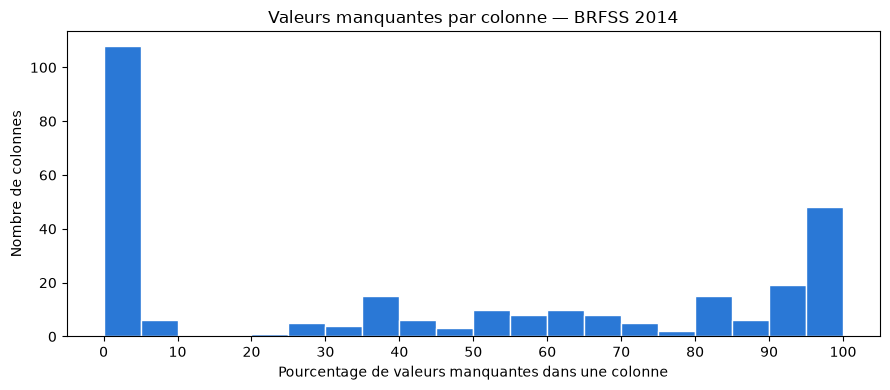

In [13]:
print(f"Taux global de valeurs manquantes : {taux_manquants.mean():.1f} %")
print(f"Colonnes sans valeur manquante : {taux_manquants.eq(0).sum()}")
print(f"Colonnes avec plus de 50 % de valeurs manquantes : {taux_manquants.gt(50).sum()}")
print(f"Colonnes entièrement vides : {taux_manquants.eq(100).sum()}")

plt.figure(figsize=(9, 4))
plt.hist(taux_manquants, bins=range(0, 101, 5), color="#2a78d6", edgecolor="white")

plt.title("Valeurs manquantes par colonne — BRFSS 2014")
plt.xlabel("Pourcentage de valeurs manquantes dans une colonne")
plt.ylabel("Nombre de colonnes")
plt.xticks(range(0, 101, 10))
plt.tight_layout()
plt.show()

Dans le fichier BRFSS 2014, 44,1 % des cellules sont manquantes. Parmi les 279 colonnes, 60 sont complètes, 131 ont plus de 50 % de valeurs manquantes et une est entièrement vide. L’histogramme montre deux concentrations, l’une entre 0 et 5 % de données manquantes et l’autre entre 95 et 100 %. Les valeurs manquantes sont donc réparties de façon très inégale entre les variables. Pour la suite, on examinera le taux de valeurs manquantes des colonnes retenues pour le projet.

3-Construction de la variable cible

In [14]:
reponses = {
    1: "Oui",
    2: "Oui, uniquement pendant la grossesse",
    3: "Non",
    4: "Prédiabète",
    7: "Ne sait pas",
    9: "Refus de répondre"
}

statut = df["DIABETE3"].map(reponses)
statut = statut.mask(df["DIABETE3"].isna(), "Valeur manquante")
statut = statut.fillna("Code inattendu")

effectifs = statut.value_counts()

tableau_diabete = pd.DataFrame({
    "Effectif": effectifs,
    "% des répondants": (effectifs / len(df) * 100).round(2)
})

display(tableau_diabete)

,Effectif,% des répondants
DIABETE3,,
Non,390827,84.11
Oui,61118,13.15
Prédiabète,7668,1.65
"Oui, uniquement pendant la grossesse",4207,0.91
Ne sait pas,551,0.12
Refus de répondre,291,0.06
Valeur manquante,2,0.00


3.1 Cible binaire et répartition des classes

,Effectif,Pourcentage (%)
Non,390827,86.48
Oui,61118,13.52


Répondants retenus : 451,945
Répondants hors de la cible binaire : 12,719


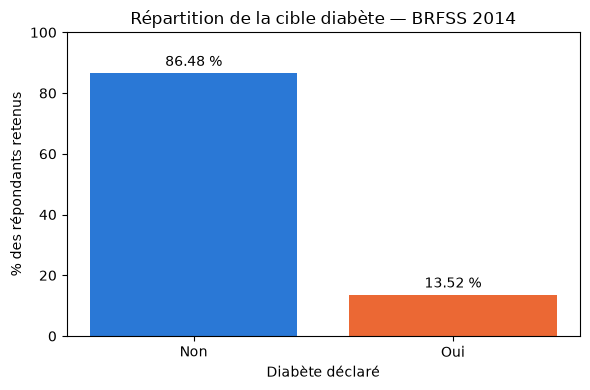

In [15]:
import matplotlib.pyplot as plt

# Recoder les réponses dans une nouvelle série
cible_diabete = df["DIABETE3"].map({1: 1, 3: 0}).astype("Int64")

# Compter les réponses retenues
effectifs = cible_diabete.value_counts().reindex([0, 1], fill_value=0)
pourcentages = (effectifs / effectifs.sum() * 100).round(2)
etiquettes = ["Non", "Oui"]

display(pd.DataFrame({
    "Effectif": effectifs.to_numpy(),
    "Pourcentage (%)": pourcentages.to_numpy()
}, index=etiquettes))

print(f"Répondants retenus : {cible_diabete.notna().sum():,}")
print(f"Répondants hors de la cible binaire : {cible_diabete.isna().sum():,}")

# Tracer la répartition de la cible
fig, ax = plt.subplots(figsize=(6, 4))
barres = ax.bar(etiquettes, pourcentages.to_numpy(), color=["#2a78d6", "#eb6834"])
ax.bar_label(barres, fmt="%.2f %%", padding=3)
ax.set(title="Répartition de la cible diabète — BRFSS 2014",
       xlabel="Diabète déclaré", ylabel="% des répondants retenus", ylim=(0, 100))
plt.tight_layout()
plt.show()

4. Sélection et nettoyage des variables explicatives

In [16]:
variables = ["_AGEG5YR", "SEX", "_BMI5", "GENHLTH", "EXERANY2"]

# Garder les répondants dont la cible vaut 0 ou 1
retenus = cible_diabete.notna()
donnees_eda = df.loc[retenus, variables].copy()

donnees_eda["diabete"] = cible_diabete.loc[retenus]

print(f"Nombre de répondants retenus : {len(donnees_eda):,}")
display(donnees_eda.head())

# Mesurer les valeurs manquantes de chaque variable
diagnostic_variables = pd.DataFrame({
    "Nombre de valeurs manquantes": donnees_eda[variables].isna().sum(),
    "% de valeurs manquantes": donnees_eda[variables].isna().mean().mul(100)
})

display(diagnostic_variables.sort_values("% de valeurs manquantes", ascending=False).round(2))

Nombre de répondants retenus : 451,945


,_AGEG5YR,SEX,_BMI5,GENHLTH,EXERANY2,diabete
0,9.0,2.0,2551.0,5.0,2.0,1
1,11.0,1.0,2495.0,3.0,1.0,0
2,7.0,1.0,3730.0,1.0,1.0,0
3,10.0,2.0,5442.0,3.0,2.0,1
4,10.0,2.0,3712.0,3.0,2.0,0


,Nombre de valeurs manquantes,% de valeurs manquantes
_BMI5,29592,6.55
EXERANY2,4,0.00
GENHLTH,4,0.00
_AGEG5YR,0,0.00
SEX,0,0.00


4.1 Recodage des réponses spéciales

In [17]:
# Créer une copie pour comparer avant et après le recodage
donnees_propres = donnees_eda.copy()

codes_manquants = {
    "GENHLTH": [7, 9],
    "EXERANY2": [7, 9],
    "_AGEG5YR": [14]
}

for colonne, codes in codes_manquants.items():
    donnees_propres[colonne] = donnees_propres[colonne].mask(
        donnees_propres[colonne].isin(codes)
    )

donnees_propres["IMC"] = donnees_propres["_BMI5"] / 100

comparaison = pd.DataFrame({
    "Valeurs manquantes avant": donnees_eda[variables].isna().sum(),
    "Valeurs manquantes après": donnees_propres[variables].isna().sum()
})

display(comparaison)

,Valeurs manquantes avant,Valeurs manquantes après
_AGEG5YR,0,5527
SEX,0,0
_BMI5,29592,29592
GENHLTH,4,1601
EXERANY2,4,1652


4.2 Distribution de l’IMC

count    422353.00
mean         27.85
std           6.10
min          12.01
25%          23.71
50%          26.78
75%          30.85
max          99.63
Name: IMC, dtype: float64

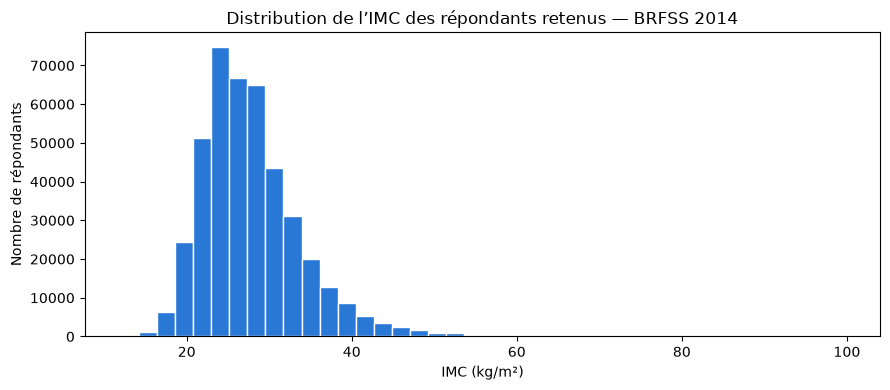

In [18]:
import matplotlib.pyplot as plt

imc = donnees_propres["IMC"].dropna()

display(imc.describe().round(2))

plt.figure(figsize=(9, 4))
plt.hist(imc, bins=40, color="#2a78d6", edgecolor="white")
plt.title("Distribution de l’IMC des répondants retenus — BRFSS 2014")
plt.xlabel("IMC (kg/m²)")
plt.ylabel("Nombre de répondants")
plt.tight_layout()
plt.show()

Les IMC observés se concentrent principalement entre 20 et 35 kg/m², avec un pic autour de 24–25 kg/m². La distribution est asymétrique à droite : les effectifs diminuent à mesure que l’IMC augmente, et quelques valeurs élevées prolongent la distribution. La médiane exacte se lit à la ligne 50 % du tableau describe().

,Effectif,Q1,Médiane,Q3
Non,365249,23.41,26.50,30.11
Oui,57104,26.63,30.41,35.15


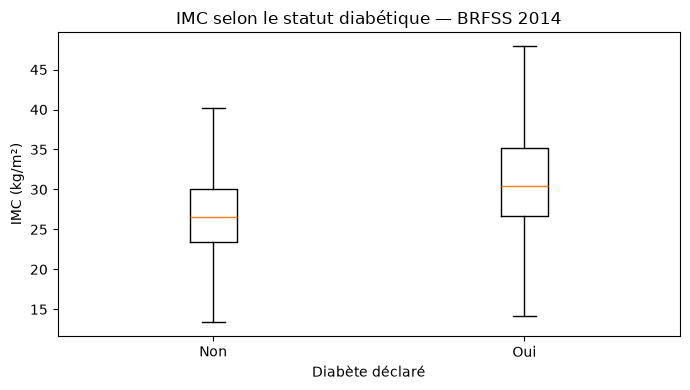

In [19]:
imc_non = donnees_propres.loc[donnees_propres["diabete"].eq(0), "IMC"].dropna()
imc_oui = donnees_propres.loc[donnees_propres["diabete"].eq(1), "IMC"].dropna()

resume = pd.DataFrame({
    "Effectif": [len(imc_non), len(imc_oui)],
    "Q1": [imc_non.quantile(0.25), imc_oui.quantile(0.25)],
    "Médiane": [imc_non.median(), imc_oui.median()],
    "Q3": [imc_non.quantile(0.75), imc_oui.quantile(0.75)]
}, index=["Non", "Oui"])

display(resume.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([imc_non, imc_oui], showfliers=False)
ax.set_xticks([1, 2], ["Non", "Oui"])
ax.set_title("IMC selon le statut diabétique — BRFSS 2014")
ax.set_xlabel("Diabète déclaré")
ax.set_ylabel("IMC (kg/m²)")
plt.tight_layout()
plt.show()

L’IMC médian est plus élevé chez les répondants qui déclarent un diabète, autour de 30 kg/m², contre environ 26,5 kg/m² dans le groupe « Non ». La boîte du groupe « Oui » est plus haute, ce qui indique une dispersion plus importante des 50 % centraux. Les deux boîtes se chevauchent. Le graphique montre une association dans cet échantillon, sans établir de relation de cause à effet.

,repondants,cas_declares,pourcentage
_AGEG5YR,,,
18–24,23871,257,1.08
25–29,19475,323,1.66
30–34,22995,606,2.64
35–39,24654,947,3.84
40–44,27787,1669,6.01
45–49,31818,2716,8.54
50–54,42201,4888,11.58
55–59,48097,6980,14.51
60–64,51093,9195,18.0


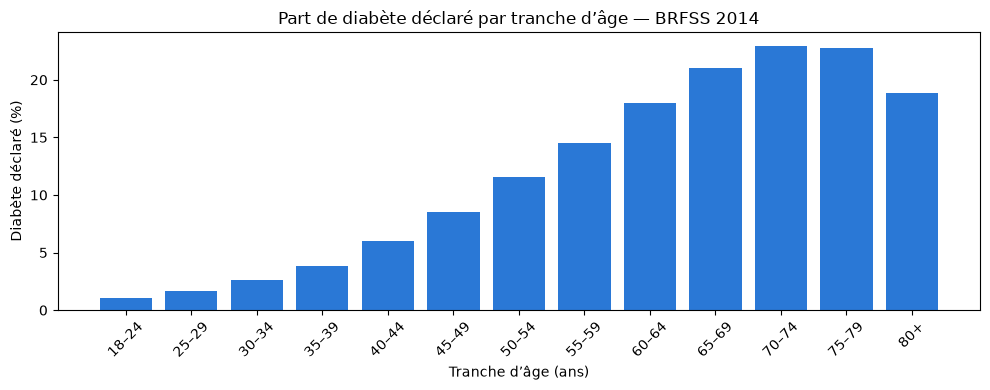

In [20]:
tranches_age = [
    "18–24", "25–29", "30–34", "35–39", "40–44", "45–49",
    "50–54", "55–59", "60–64", "65–69", "70–74", "75–79", "80+"
]

par_age = donnees_propres.groupby("_AGEG5YR")["diabete"].agg(
    repondants="size",
    cas_declares="sum"
)

par_age["pourcentage"] = par_age["cas_declares"] / par_age["repondants"] * 100
par_age = par_age.rename(index=dict(enumerate(tranches_age, start=1)))

display(par_age.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(par_age.index, par_age["pourcentage"], color="#2a78d6")
ax.set_title("Part de diabète déclaré par tranche d’âge — BRFSS 2014")
ax.set_xlabel("Tranche d’âge (ans)")
ax.set_ylabel("Diabète déclaré (%)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

La part de répondants déclarant un diabète augmente avec l’âge, passant d’environ 1 % chez les 18–24 ans à 23 % chez les 70–74 ans. Elle reste proche de ce niveau chez les 75–79 ans, puis descend à environ 19 % chez les 80 ans et plus. Ces pourcentages décrivent les répondants retenus dans chaque tranche d’âge.

,repondants,cas_declares,pourcentage
EXERANY2,,,
Avec activité physique,340767,37519,11.01
Sans activité physique,109526,23379,21.35


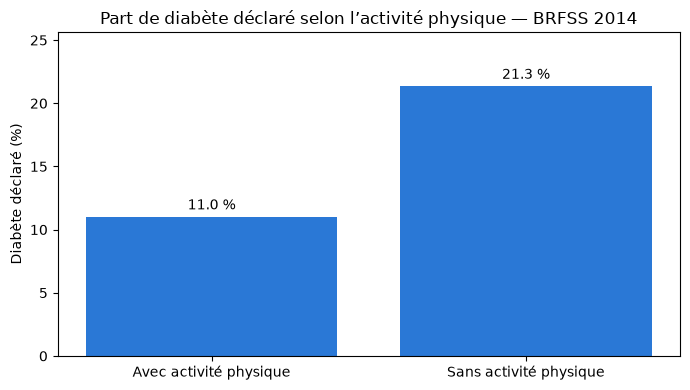

In [21]:
par_activite = donnees_propres.groupby("EXERANY2")["diabete"].agg(
    repondants="size",
    cas_declares="sum"
)

par_activite["pourcentage"] = (
    par_activite["cas_declares"] / par_activite["repondants"] * 100
)
par_activite = par_activite.rename(index={
    1: "Avec activité physique",
    2: "Sans activité physique"
})

display(par_activite.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
barres = ax.bar(
    par_activite.index, par_activite["pourcentage"], color="#2a78d6"
)
ax.bar_label(barres, fmt="%.1f %%", padding=3)
ax.set_title("Part de diabète déclaré selon l’activité physique — BRFSS 2014")
ax.set_ylabel("Diabète déclaré (%)")
ax.set_ylim(0, par_activite["pourcentage"].max() * 1.2)
plt.tight_layout()
plt.show()

Dans l’échantillon étudié, 21,3 % des répondants sans activité physique déclarée ont déclaré un diabète, contre 11,0 % de ceux ayant déclaré une activité physique. L’écart est de 10,3 points de pourcentage. Cette comparaison est descriptive et ne tient pas compte des différences d’âge ou d’IMC entre les groupes.

,repondants,cas_declares,pourcentage
GENHLTH,,,
Excellente,80633,2131,2.64
Très bonne,148109,9975,6.73
Bonne,138050,22294,16.15
Passable,59583,17378,29.17
Mauvaise,23969,9023,37.64


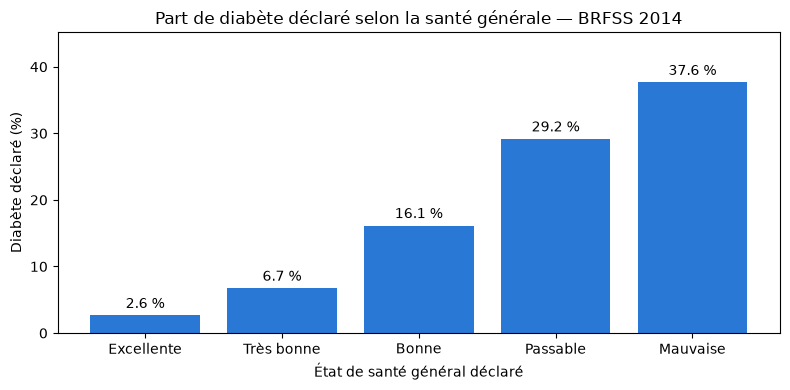

In [22]:
etiquettes_sante = {
    1: "Excellente",
    2: "Très bonne",
    3: "Bonne",
    4: "Passable",
    5: "Mauvaise"
}

par_sante = donnees_propres.groupby("GENHLTH")["diabete"].agg(
    repondants="size",
    cas_declares="sum"
)

par_sante["pourcentage"] = (
    par_sante["cas_declares"] / par_sante["repondants"] * 100
)
par_sante = par_sante.sort_index().rename(index=etiquettes_sante)

display(par_sante.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
barres = ax.bar(par_sante.index, par_sante["pourcentage"], color="#2a78d6")
ax.bar_label(barres, fmt="%.1f %%", padding=3)
ax.set_title("Part de diabète déclaré selon la santé générale — BRFSS 2014")
ax.set_xlabel("État de santé général déclaré")
ax.set_ylabel("Diabète déclaré (%)")
ax.set_ylim(0, par_sante["pourcentage"].max() * 1.2)
plt.tight_layout()
plt.show()

La part de diabète déclaré augmente à mesure que l’état de santé perçu se dégrade. Elle passe de 2,6 % chez les répondants qui jugent leur santé excellente à 37,6 % chez ceux qui la jugent mauvaise, soit un écart de 35 points de pourcentage. Ces résultats décrivent une association dans l’échantillon étudié.

,repondants,cas_declares,pourcentage
SEX,,,
Hommes,189318,26586,14.04
Femmes,262627,34532,13.15


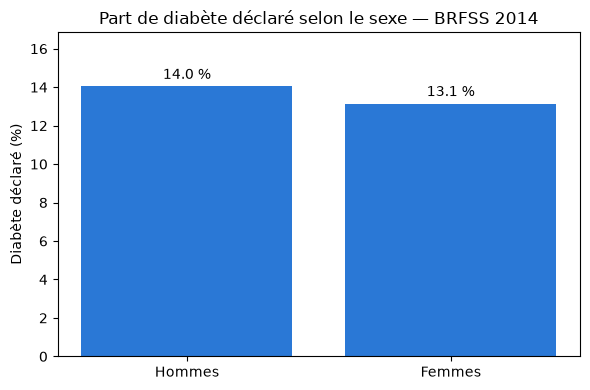

In [23]:
par_sexe = donnees_propres.groupby("SEX")["diabete"].agg(
    repondants="size",
    cas_declares="sum"
)

par_sexe["pourcentage"] = (
    par_sexe["cas_declares"] / par_sexe["repondants"] * 100
)
par_sexe = par_sexe.rename(index={1: "Hommes", 2: "Femmes"})

display(par_sexe.round(2))

fig, ax = plt.subplots(figsize=(6, 4))
barres = ax.bar(par_sexe.index, par_sexe["pourcentage"], color="#2a78d6")
ax.bar_label(barres, fmt="%.1f %%", padding=3)
ax.set_title("Part de diabète déclaré selon le sexe — BRFSS 2014")
ax.set_ylabel("Diabète déclaré (%)")
ax.set_ylim(0, par_sexe["pourcentage"].max() * 1.2)
plt.tight_layout()
plt.show()

Dans l’échantillon retenu, 14,0 % des hommes et 13,1 % des femmes ont déclaré un diabète. L’écart observé est d’environ 0,9 point de pourcentage.

Le fichier BRFSS 2014 contient 464 664 répondants et 279 variables. Après le recodage de la variable cible, 451 945 répondants ont été retenus pour la comparaison binaire. Parmi eux, 13,52 % ont déclaré un diabète, ce qui montre un déséquilibre entre les classes.

Le diabète déclaré est plus fréquent dans les tranches d’âge élevées, chez les répondants sans activité physique déclarée et chez ceux qui jugent leur santé générale moins bonne. L’IMC médian est également plus élevé dans le groupe qui déclare un diabète. L’écart observé selon le sexe est plus faible. Ces résultats sont descriptifs et non pondérés. Ils concernent les répondants étudiés et ne permettent pas d’établir des liens de cause à effet.

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

colonnes_relations = [
    "GENHLTH", "PHYSHLTH", "MENTHLTH", "_BMI5",
    "_AGEG5YR", "_INCOMG", "ASTHMA3"
]

relations = df[colonnes_relations].copy()

codes_manquants_relations = {
    "GENHLTH": [7, 9],
    "PHYSHLTH": [77, 99],
    "MENTHLTH": [77, 99],
    "_AGEG5YR": [14],
    "_INCOMG": [9],
    "ASTHMA3": [7, 9]
}

for colonne, codes in codes_manquants_relations.items():
    relations[colonne] = relations[colonne].mask(relations[colonne].isin(codes))

for colonne in ["PHYSHLTH", "MENTHLTH"]:
    relations[colonne] = relations[colonne].replace(88, 0)

relations["IMC"] = relations["_BMI5"] / 100
relations["diabete"] = cible_diabete

display(relations.head())

,GENHLTH,PHYSHLTH,MENTHLTH,_BMI5,_AGEG5YR,_INCOMG,ASTHMA3,IMC,diabete
0,5.0,25.0,5.0,2551.0,9.0,5.0,2.0,25.51,1
1,3.0,7.0,14.0,2495.0,11.0,2.0,2.0,24.95,0
2,1.0,0.0,0.0,3730.0,7.0,5.0,2.0,37.30,0
3,3.0,NaN,NaN,5442.0,10.0,3.0,1.0,54.42,1
4,3.0,2.0,0.0,3712.0,10.0,2.0,2.0,37.12,0


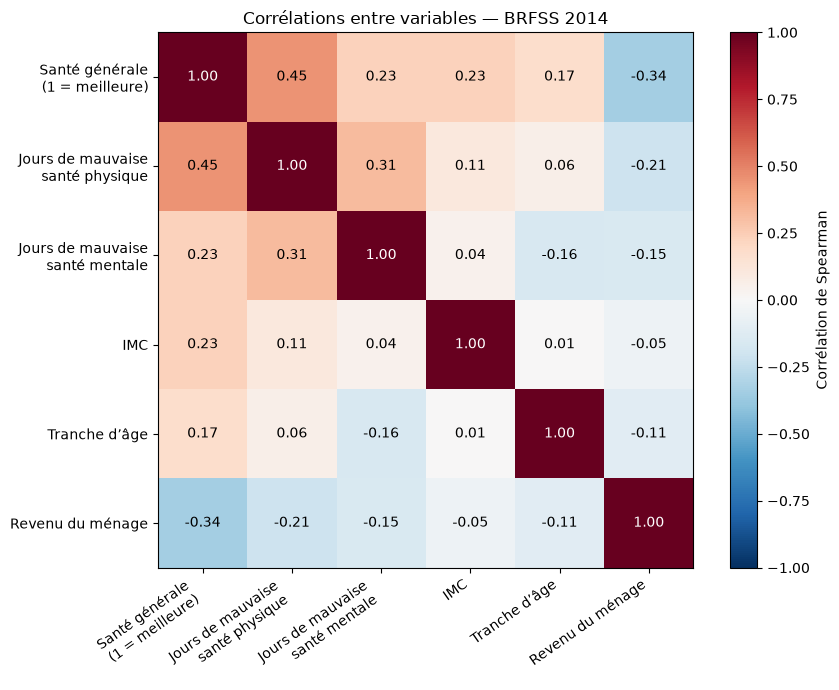

In [25]:
variables_correlation = {
    "GENHLTH": "Santé générale\n(1 = meilleure)",
    "PHYSHLTH": "Jours de mauvaise\nsanté physique",
    "MENTHLTH": "Jours de mauvaise\nsanté mentale",
    "IMC": "IMC",
    "_AGEG5YR": "Tranche d’âge",
    "_INCOMG": "Revenu du ménage"
}

matrice = (
    relations[list(variables_correlation)]
    .rename(columns=variables_correlation)
    .corr(method="spearman")
)

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(matrice, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(matrice)), matrice.columns, rotation=35, ha="right")
ax.set_yticks(range(len(matrice)), matrice.index)

for ligne in range(len(matrice)):
    for colonne in range(len(matrice)):
        valeur = matrice.iloc[ligne, colonne]
        couleur = "white" if abs(valeur) > 0.5 else "black"
        ax.text(colonne, ligne, f"{valeur:.2f}",
                ha="center", va="center", color=couleur)

fig.colorbar(image, ax=ax, label="Corrélation de Spearman")
ax.set_title("Corrélations entre variables — BRFSS 2014")
plt.tight_layout()
plt.show()

GENHLTH,Excellente,Très bonne,Bonne,Passable,Mauvaise
_INCOMG,,,,,
< 15 000 $,8.7,16.2,30.7,27.9,16.5
15 000 à < 25 000 $,10.7,23.5,35.3,21.2,9.3
25 000 à < 35 000 $,13.2,30.4,35.4,15.7,5.3
35 000 à < 50 000 $,16.3,34.8,34.0,11.4,3.5
50 000 $ ou plus,24.6,41.5,26.3,6.2,1.5


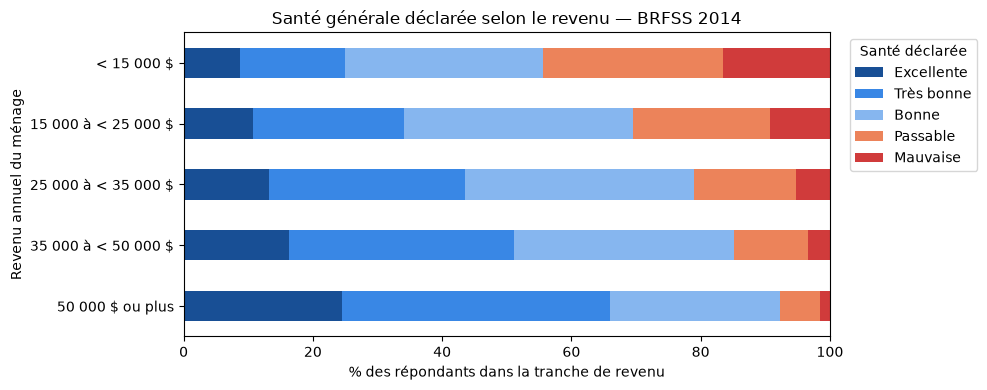

In [26]:
revenus = {
    1: "< 15 000 $",
    2: "15 000 à < 25 000 $",
    3: "25 000 à < 35 000 $",
    4: "35 000 à < 50 000 $",
    5: "50 000 $ ou plus"
}

sante = {
    1: "Excellente",
    2: "Très bonne",
    3: "Bonne",
    4: "Passable",
    5: "Mauvaise"
}

sante_revenu = pd.crosstab(
    relations["_INCOMG"],
    relations["GENHLTH"],
    normalize="index"
).mul(100)

sante_revenu = (
    sante_revenu.reindex(index=list(revenus), columns=list(sante))
    .rename(index=revenus, columns=sante)
)

display(sante_revenu.round(1))

ax = sante_revenu.plot(
    kind="barh", stacked=True, figsize=(10, 4),
    color=["#184f95", "#3987e5", "#86b6ef", "#ec835a", "#d03b3b"]
)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% des répondants dans la tranche de revenu")
ax.set_ylabel("Revenu annuel du ménage")
ax.set_title("Santé générale déclarée selon le revenu — BRFSS 2014")
ax.legend(title="Santé déclarée", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

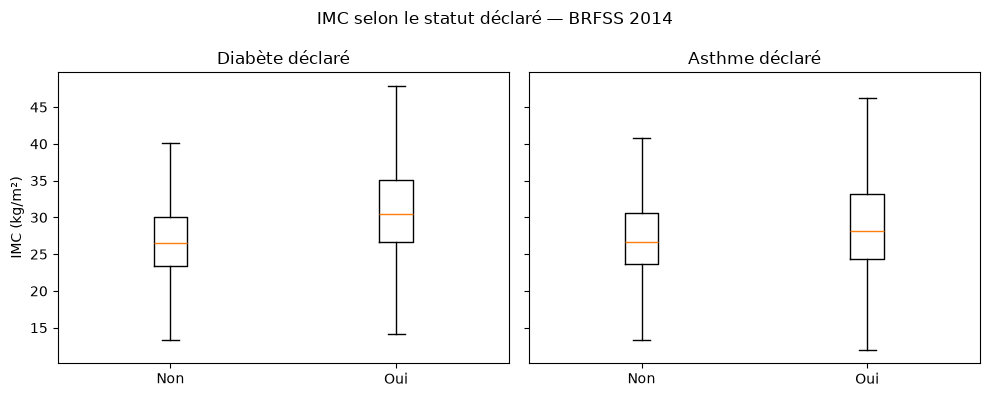

,Maladie,Groupe,Effectif,IMC médian
0,Diabète déclaré,Non,365249,26.50
1,Diabète déclaré,Oui,57104,30.41
2,Asthme déclaré,Non,375423,26.63
3,Asthme déclaré,Oui,57289,28.19


In [27]:
comparaisons = [
    ("diabete", 0, 1, "Diabète déclaré"),
    ("ASTHMA3", 2, 1, "Asthme déclaré")
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
lignes_resume = []

for ax, (colonne, code_non, code_oui, titre) in zip(axes, comparaisons):
    imc_non = relations.loc[relations[colonne].eq(code_non), "IMC"].dropna()
    imc_oui = relations.loc[relations[colonne].eq(code_oui), "IMC"].dropna()

    ax.boxplot([imc_non, imc_oui], showfliers=False)
    ax.set_xticks([1, 2], ["Non", "Oui"])
    ax.set_title(titre)

    for groupe, valeurs in [("Non", imc_non), ("Oui", imc_oui)]:
        lignes_resume.append({
            "Maladie": titre,
            "Groupe": groupe,
            "Effectif": len(valeurs),
            "IMC médian": valeurs.median()
        })

axes[0].set_ylabel("IMC (kg/m²)")
fig.suptitle("IMC selon le statut déclaré — BRFSS 2014")
plt.tight_layout()
plt.show()

display(pd.DataFrame(lignes_resume).round(2))

In [28]:
nb_manquants = df.isna().sum()

print(f"Nombre total de cellules : {df.size:,}")
print(f"Cellules manquantes brutes : {nb_manquants.sum():,}")
print(f"Lignes sans valeur manquante brute : {df.notna().all(axis=1).sum():,}")
print(f"Lignes entièrement identiques à une ligne précédente : {df.duplicated().sum():,}")

verification = []

for colonne, codes in codes_manquants_relations.items():
    verification.append({
        "Variable": colonne,
        "Manquants avant": df[colonne].isna().sum(),
        "Codes spéciaux repérés": df[colonne].isin(codes).sum(),
        "Manquants après": relations[colonne].isna().sum()
    })

display(pd.DataFrame(verification).set_index("Variable"))

for colonne in ["PHYSHLTH", "MENTHLTH"]:
    print(f"{colonne} — réponses 88 recodées en 0 jour : {df[colonne].eq(88).sum():,}")

print("\nContrôle de la cible binaire :")
display(cible_diabete.value_counts(dropna=False))

Nombre total de cellules : 129,641,256
Cellules manquantes brutes : 57,196,182
Lignes sans valeur manquante brute : 0
Lignes entièrement identiques à une ligne précédente : 0


,Manquants avant,Codes spéciaux repérés,Manquants après
Variable,,,
GENHLTH,4,1688,1692
PHYSHLTH,4,10299,10303
MENTHLTH,1,7961,7962
_AGEG5YR,0,5778,5778
_INCOMG,0,71396,71396
ASTHMA3,0,1505,1505


PHYSHLTH — réponses 88 recodées en 0 jour : 291,696
MENTHLTH — réponses 88 recodées en 0 jour : 319,131

Contrôle de la cible binaire :


DIABETE3
0       390827
1        61118
<NA>     12719
Name: count, dtype: Int64